<a href="https://colab.research.google.com/github/srushtisatav07/eda-/blob/main/linear_registration_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Linear Regression from Scratch

## Project Overview
This project predicts house prices using Linear Regression implemented with NumPy.

## Objectives
- Generate sample housing data.
- Train a linear regression model using the normal equation.
- Implement gradient descent.
- Evaluate predictions using RMSE and R².
- Visualize predicted prices against actual prices.


In [1]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Generate house sizes in square feet
house_sizes = np.random.randint(500, 2500, 100)

# Generate house prices in lakhs
noise = np.random.normal(0, 3, 100)
house_prices = 10 + 0.04 * house_sizes + noise

print("First 10 house sizes:")
print(house_sizes[:10])

print("\nFirst 10 house prices:")
print(house_prices[:10])

print("\nTotal houses:", len(house_sizes))


First 10 house sizes:
[1626 1959 1360 1794 1630 1595 2224 1544 2138  621]

First 10 house prices:
[75.69591495 91.00528312 61.37274397 77.01011736 77.52110125 72.18557502
 94.91996571 69.1182262  92.12834309 35.24328665]

Total houses: 100


In [2]:

# Convert house sizes into a NumPy column
X = house_sizes.reshape(-1, 1)

# Convert house prices into a NumPy column
y = house_prices.reshape(-1, 1)

# Add a column of ones for the intercept
X_b = np.c_[np.ones((100, 1)), X]

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("Shape of X_b:", X_b.shape)

print("\nFirst 5 rows of X_b:")
print(X_b[:5])


Shape of X: (100, 1)
Shape of y: (100, 1)
Shape of X_b: (100, 2)

First 5 rows of X_b:
[[1.000e+00 1.626e+03]
 [1.000e+00 1.959e+03]
 [1.000e+00 1.360e+03]
 [1.000e+00 1.794e+03]
 [1.000e+00 1.630e+03]]


In [3]:

# Calculate the normal equation
theta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

print("Intercept:", theta[0, 0])
print("Slope:", theta[1, 0])


Intercept: 10.436946937827331
Slope: 0.039700226512527935


In [4]:

# Predict prices using the normal equation
y_pred = X_b @ theta

print("Actual prices (first 5):")
print(y[:5])

print("\nPredicted prices (first 5):")
print(y_pred[:5])


Actual prices (first 5):
[[75.69591495]
 [91.00528312]
 [61.37274397]
 [77.01011736]
 [77.52110125]]

Predicted prices (first 5):
[[74.98951525]
 [88.20969068]
 [64.42925499]
 [81.6591533 ]
 [75.14831615]]


In [5]:

det = np.linalg.det(X_b.T @ X_b)

print("Determinant:", det)

if abs(det) > 1e-10:
    print("Matrix is invertible.")
else:
    print("Matrix is not invertible.")


Determinant: 2953534459.000001
Matrix is invertible.


In [6]:

# Root Mean Squared Error
rmse = np.sqrt(np.mean((y - y_pred) ** 2))

# R-squared score
ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r2 = 1 - (ss_res / ss_tot)

print("RMSE:", rmse)
print("R² Score:", r2)


RMSE: 2.8337259239195323
R² Score: 0.983042571261307


In [7]:

# Initialize parameters
theta_gd = np.zeros((2, 1))

# Set learning rate and iterations
learning_rate = 0.0000001
iterations = 10000
m = len(y)

# Perform gradient descent
for i in range(iterations):
    predictions = X_b @ theta_gd
    gradients = (2 / m) * X_b.T @ (predictions - y)
    theta_gd = theta_gd - learning_rate * gradients

print("Gradient Descent Intercept:", theta_gd[0, 0])
print("Gradient Descent Slope:", theta_gd[1, 0])


Gradient Descent Intercept: 0.0024815727151535796
Gradient Descent Slope: 0.04588505936189743


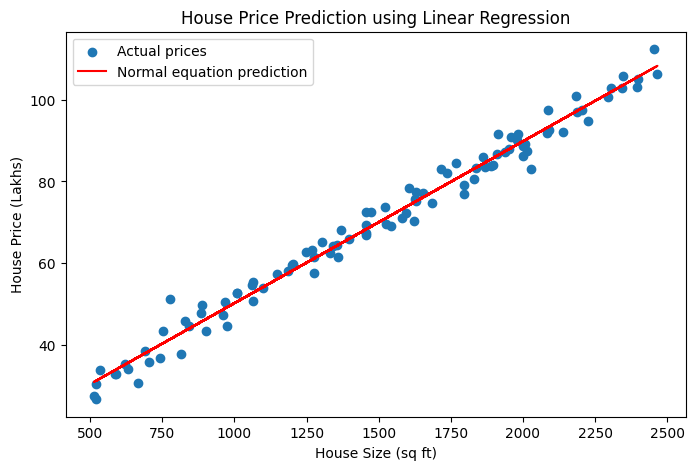

In [8]:

# Plot actual data and the regression line
plt.figure(figsize=(8, 5))

plt.scatter(X[:, 0], y[:, 0], label="Actual prices")
plt.plot(X[:, 0], y_pred[:, 0], color="red",
         label="Normal equation prediction")

plt.xlabel("House Size (sq ft)")
plt.ylabel("House Price (Lakhs)")
plt.title("House Price Prediction using Linear Regression")
plt.legend()
plt.show()


In [9]:

print("Normal Equation")
print("Intercept:", theta[0, 0])
print("Slope:", theta[1, 0])

print("\nGradient Descent")
print("Intercept:", theta_gd[0, 0])
print("Slope:", theta_gd[1, 0])


Normal Equation
Intercept: 10.436946937827331
Slope: 0.039700226512527935

Gradient Descent
Intercept: 0.0024815727151535796
Slope: 0.04588505936189743



## Conclusion

In this project, Linear Regression was implemented from scratch using NumPy. Synthetic housing data was generated to study the relationship between house size and price.

The normal equation was used to calculate the model parameters, while gradient descent was implemented as an iterative optimization method. The model was evaluated using RMSE and R², and its predictions were visualized using Matplotlib.

This project demonstrates the use of NumPy arrays, matrix multiplication, matrix inversion, gradient descent, and basic machine learning evaluation metrics.
